# Logistic Regression on the Breast Cancer Wisconsin Dataset

This notebook walks through the same simple pipeline as `bcancer.py`, one
step at a time, with a few prints along the way so you can see what's
happening at each stage. At the end we visualize the logistic "S-curve"
(sigmoid) two different ways.


In [37]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split


## Step 1: Load the data

`load_breast_cancer()` is a small, built-in dataset — no download needed.
Each row is a tumor, each column is a measurement computed from a digitized
image (radius, texture, perimeter, concavity, etc.), and the target is
`0` (malignant) or `1` (benign).


In [38]:
data = load_breast_cancer()
# print(data)

X, y = data.data, data.target

print("X shape:", X.shape)
print("feature names:", list(data.feature_names))
print("target names:", list(data.target_names))
print("X shape:", X.shape)
print("class balance (0=malignant, 1=benign):", np.bincount(y))


X shape: (569, 30)
feature names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]
target names: [np.str_('malignant'), np.str_('benign')]
X shape: (569, 30)
class balance (0=malignant, 1=benign): [212 3

## Step 2: Train/test split

Same split as `bcancer.py` — `train_size=0.9`, holding out 10% to evaluate on.


In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=0,
    train_size=0.9,
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (512, 30)
X_test shape: (57, 30)


## Step 3: Fit a logistic regression model

Same model as `bcancer.py`: plain `LogisticRegression`, with `max_iter`
raised from the default so it reliably converges on these unscaled features.


In [40]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

## Step 4: Evaluate

`model.score` returns accuracy on held-out data.


In [41]:
accuracy = model.score(X_test, y_test)
print("accuracy:", accuracy)


accuracy: 0.9473684210526315


## Step 5: Confusion matrix

Accuracy is a single number, and it hides *how* the model gets things wrong.
A confusion matrix breaks the test-set predictions into four counts:

|                   | predicted malignant | predicted benign |
|-------------------|----------------------|-------------------|
| actual malignant  | true negative (TN)   | false positive (FP) |
| actual benign     | false negative (FN)  | true positive (TP)  |

(Using this dataset's label convention, where the target's `1` = benign and
`0` = malignant.)

For a cancer-screening model, the off-diagonal cells matter more than
accuracy alone: a **false negative** here means telling someone with a
malignant tumor "benign" and missing an actual cancer — a far costlier
mistake than a false positive, which just means extra follow-up testing on
something that turns out to be fine.


[[22  0]
 [ 3 32]]


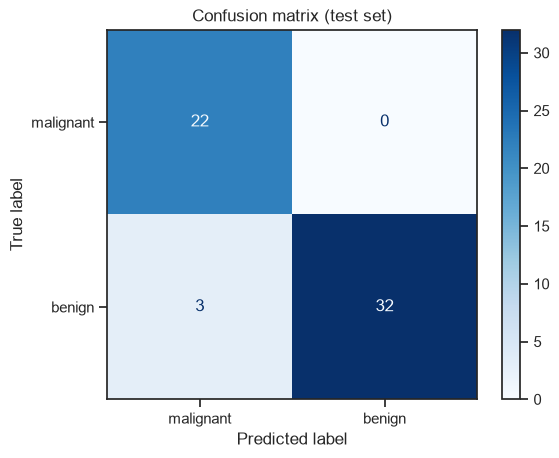

In [42]:
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()


## Step 6: What is the "S-curve"?

Logistic regression works by computing a linear score

$$z = w \cdot x + b$$

and then squashing it into a probability with the **sigmoid** function:

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

That squashing function is the classic "S-curve".

**Does an S-curve only apply to a single predictor?** The *textbook* 2D
picture (x-axis = one feature, y-axis = predicted probability) only works
directly for a single predictor, since it's a 2D plot and our model here
uses all 30 features at once — there's no single feature axis to plot the
full model against.

But the sigmoid relationship itself still holds for *any* number of
predictors, because `predict_proba` is always `sigmoid(z)` where `z` is the
(possibly many-feature) linear score. So below we show it two ways:

- **Plot A** — the *real* 30-feature model: predicted probability vs. its
  own decision score `z`. This always traces a perfect S-curve, no matter
  how many features fed into `z`.
- **Plot B** — a small, separate single-feature model, fit only for
  illustration, to show the familiar 2D textbook sigmoid.


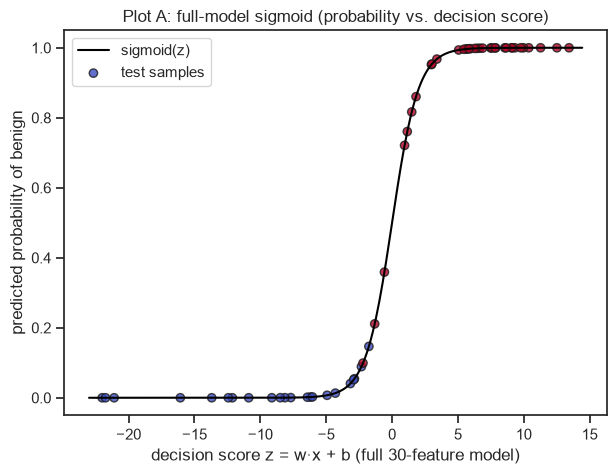

In [43]:
# Plot A: predicted probability vs. the full model's decision score z
z_test = model.decision_function(X_test)
p_test = model.predict_proba(X_test)[:, 1]

# Theoretical sigmoid curve for reference, across the observed range of z
z_line = np.linspace(z_test.min() - 1, z_test.max() + 1, 300)
p_line = 1 / (1 + np.exp(-z_line))

plt.figure(figsize=(7, 5))
plt.plot(z_line, p_line, color="black", label="sigmoid(z)")
plt.scatter(z_test, p_test, c=y_test, cmap="coolwarm", edgecolor="k", alpha=0.8,
            label="test samples")
plt.xlabel("decision score z = w·x + b (full 30-feature model)")
plt.ylabel("predicted probability of benign")
plt.title("Plot A: full-model sigmoid (probability vs. decision score)")
plt.legend()
plt.show()


## Step 7: Every single-predictor sigmoid (Plot B)

Instead of picking just one feature, let's fit a tiny one-feature logistic
regression for *every* one of the 30 features and plot each resulting
sigmoid as a small multiple. None of these are the real 30-feature model we
evaluated above — each subplot is its own small, separate "toy" fit, purely
for intuition about how that one measurement relates to the probability of
being benign. (The first panel, top-left, is `"mean radius"`.)

**Would seaborn be easier here?** For a single plot, yes — seaborn's
`regplot(..., logistic=True)` fits a one-feature logistic regression *and*
draws its sigmoid in one call, which is a lot less code than doing it by
hand with scikit-learn (fit, build an x-grid, call `predict_proba`, plot).
That's exactly what we use below, with `ci=None` so it skips the (slow)
bootstrap confidence band across all 30 small plots.

One trade-off: `regplot(logistic=True)` fits its curve using `statsmodels`
under the hood — a different library from the `scikit-learn` model used
everywhere else in this notebook — so it's an extra dependency, and each
little curve is its own independent fit rather than a view into our real
model. That's fine for this purely illustrative grid, which is why **Plot
A** (above) instead plots our actual fitted `model`'s own sigmoid.


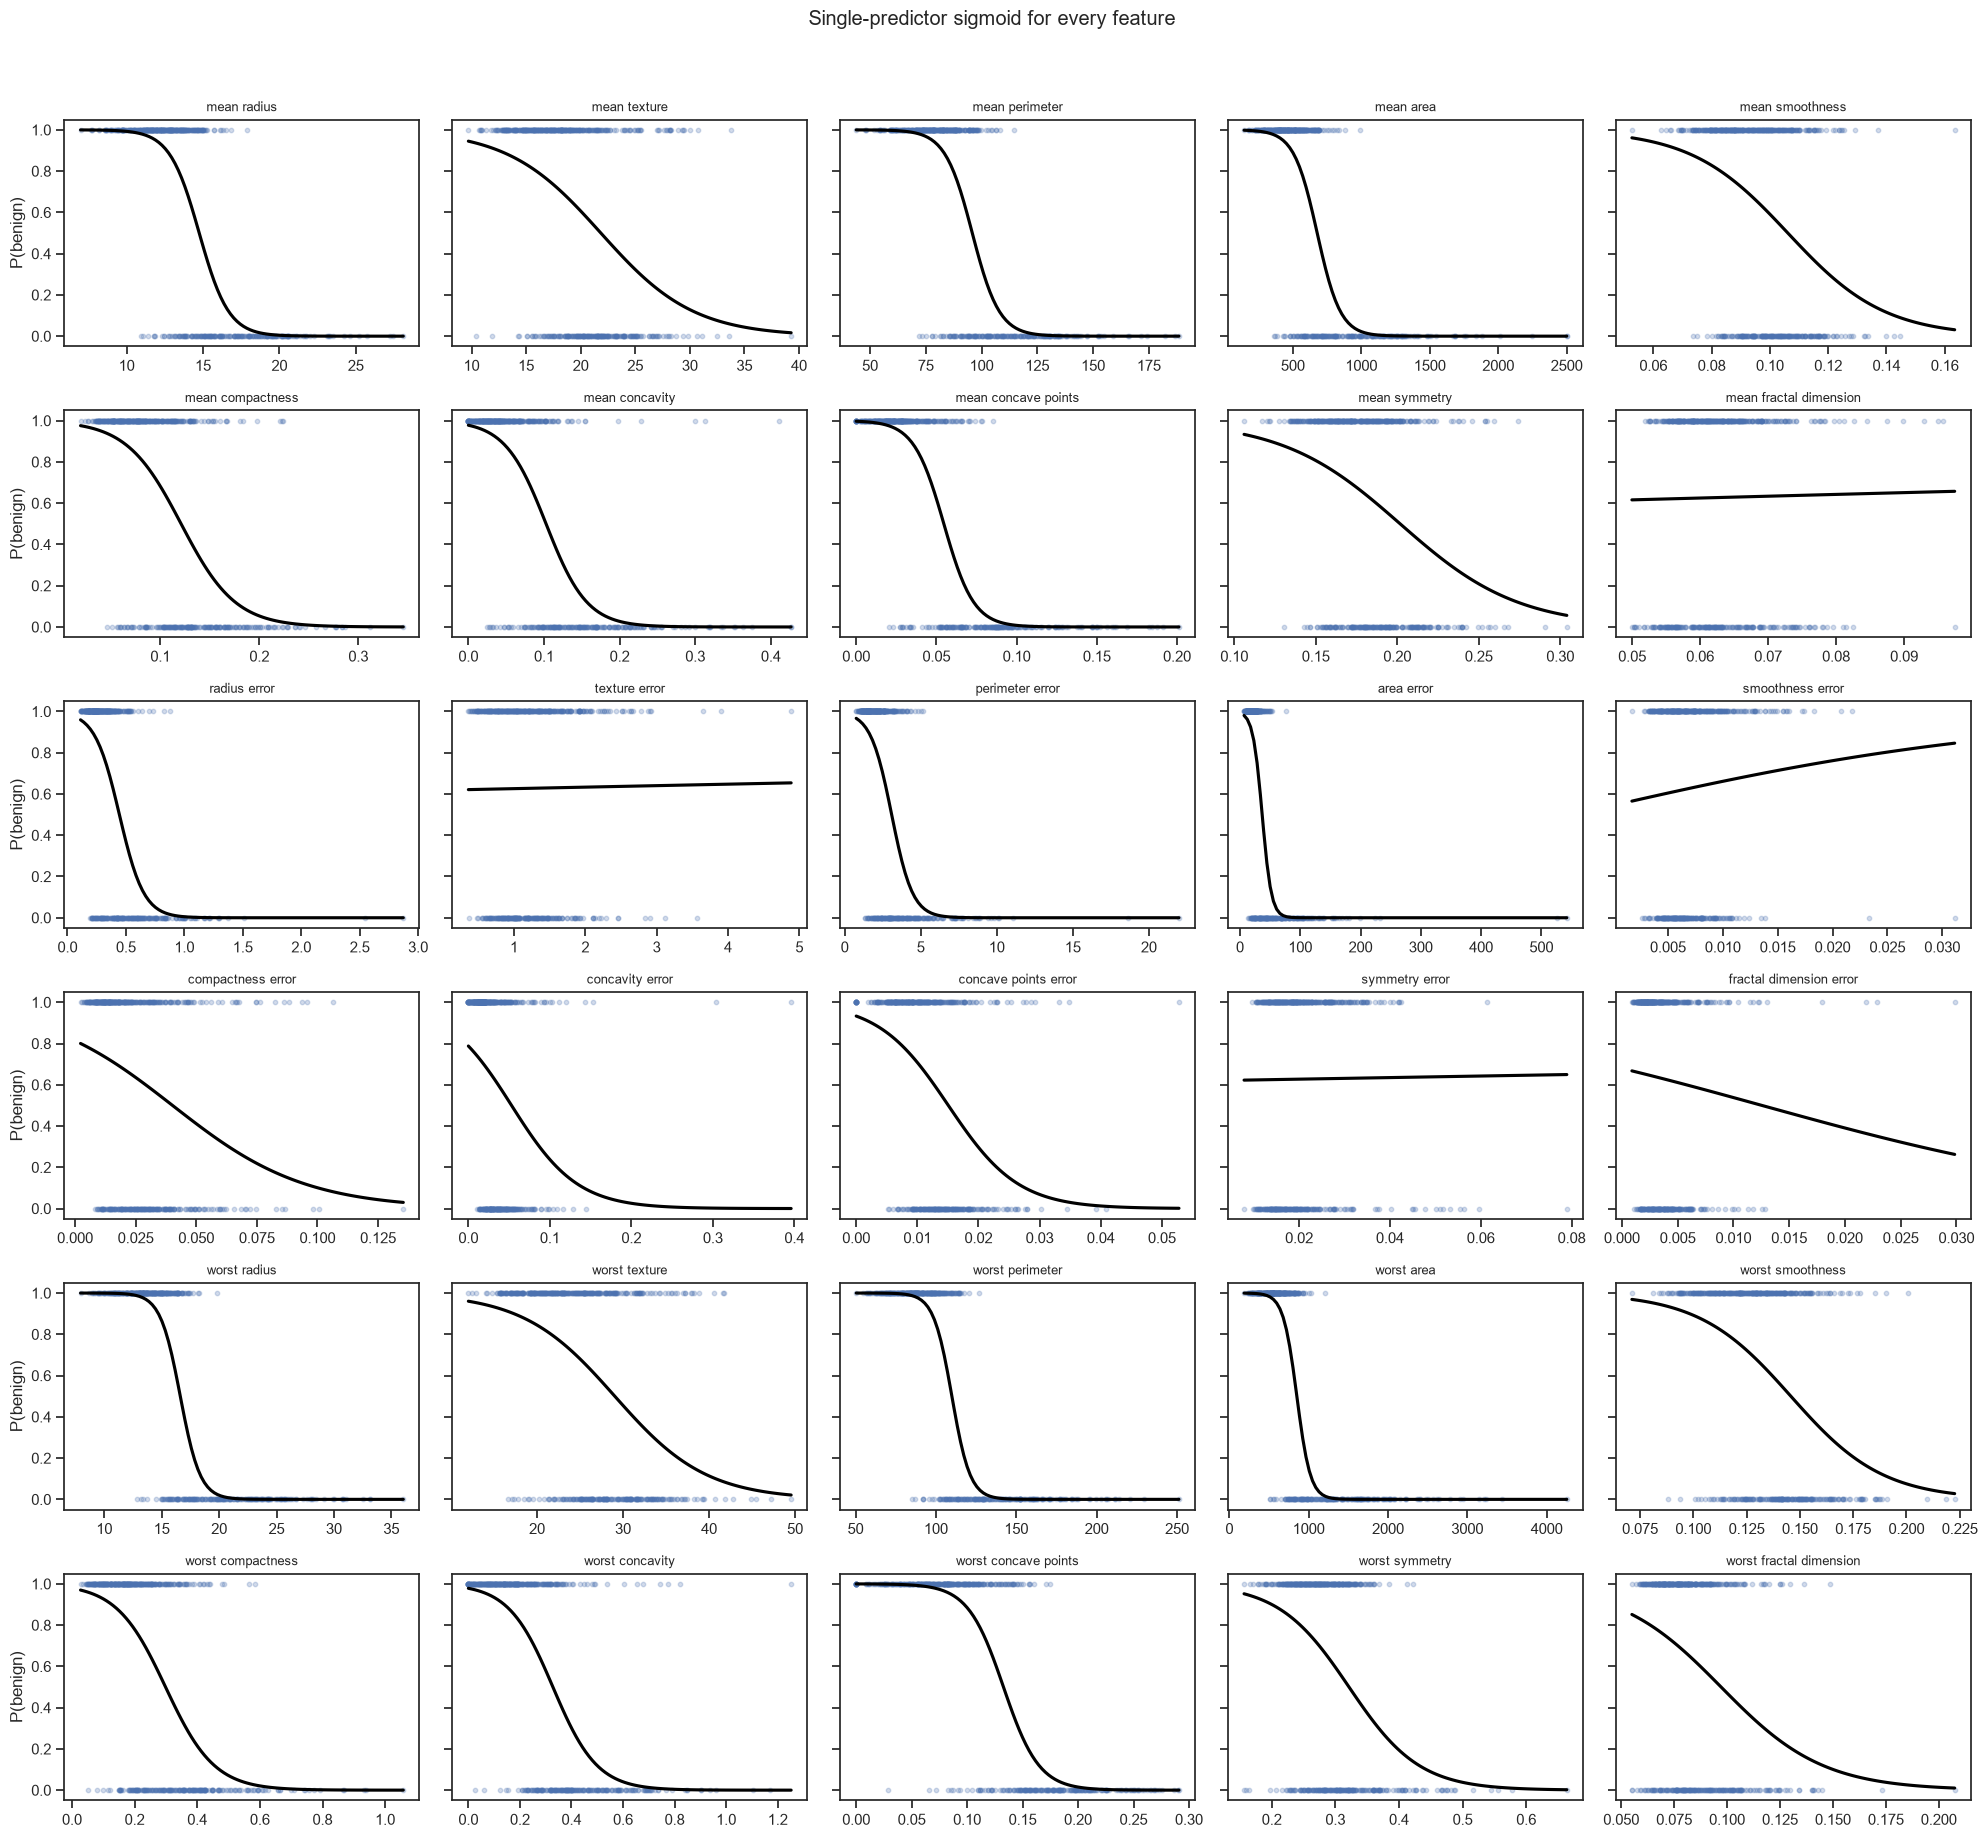

In [44]:
import seaborn as sns

sns.set_theme(style="ticks")

n_features = X.shape[1]
n_cols = 5
n_rows = -(-n_features // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), sharey=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i >= n_features:
        ax.axis("off")
        continue
    feature_name = data.feature_names[i]
    sns.regplot(
        x=X[:, i],
        y=y,
        logistic=True,
        ci=None,
        scatter_kws={"alpha": 0.25, "s": 10},
        line_kws={"color": "black"},
        ax=ax,
    )
    ax.set_title(feature_name, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("P(benign)" if i % n_cols == 0 else "")

fig.suptitle("Single-predictor sigmoid for every feature", y=1.02)
fig.tight_layout()
plt.show()


## Step 8: Reading the grid — why are some S-curves flat?

Each panel above fits an *independent* one-feature logistic regression, so
its steepness is a direct visual readout of how well that single
measurement, by itself, separates malignant from benign.

A flat, near-horizontal panel means the best-fit slope for that feature is
close to zero: the feature barely differs between the two classes, so the
fitted curve just sits near the dataset's overall base rate (~63% benign)
across the whole range, never bending into a visible "S". A steep, clean
S-shape means the opposite — there's a real difference in that measurement
between malignant and benign tumors, with a fairly sharp probability
transition somewhere in the observed range.

We can check this intuition against each feature's correlation with the
target:


In [45]:
corrs = np.array([np.corrcoef(X[:, i], y)[0, 1] for i in range(X.shape[1])])
order = np.argsort(np.abs(corrs))

print("flattest panels (|correlation| closest to 0):")
for i in order[:5]:
    print(f"  {data.feature_names[i]:28s} corr={corrs[i]:+.3f}")

print()
print("steepest panels (|correlation| closest to 1):")
for i in order[::-1][:5]:
    print(f"  {data.feature_names[i]:28s} corr={corrs[i]:+.3f}")


flattest panels (|correlation| closest to 0):
  symmetry error               corr=+0.007
  texture error                corr=+0.008
  mean fractal dimension       corr=+0.013
  smoothness error             corr=+0.067
  fractal dimension error      corr=-0.078

steepest panels (|correlation| closest to 1):
  worst concave points         corr=-0.794
  worst perimeter              corr=-0.783
  mean concave points          corr=-0.777
  worst radius                 corr=-0.776
  mean perimeter               corr=-0.743


As expected, the flattest panels are things like `symmetry error`,
`texture error`, and `mean fractal dimension` — correlations near 0 — while
the steepest are `worst concave points`, `worst perimeter`, and the
radius/area/perimeter group, all around 0.7–0.8 in magnitude. These are
classic cancer indicators: bigger, more irregular, more concave shapes tend
to be malignant.

One caveat: a few features (e.g. `worst area`, which ranges from ~185 to
~4,250) have long-tailed distributions. For those, the real 0→1 transition
can get squeezed into a narrow sliver near one edge of the x-axis, so a
genuinely informative feature can still *look* flat across most of the
plotted range — worth a second look before writing a feature off just
because its panel looks flat.

**Takeaway:** this grid works as a quick univariate screening tool. Panels
with a clear S-shape are this dataset's strongest individual predictors;
flat panels carry little standalone signal (though they could still help
the full model in combination with other features). It's also a nice
intuition check for why the 30-feature model in Plot A beats any single
feature alone: it combines several informative panels, plus some
uninformative ones whose coefficients effectively get shrunk toward zero.


## Takeaways

- The full 30-feature model and the pipeline are identical to `bcancer.py` —
  just split into labeled steps here.
- Accuracy alone hides *how* a model is wrong; the confusion matrix (Step 5)
  shows the breakdown of false positives vs. false negatives, which matters
  a lot for a medical screening task.
- `predict_proba` is always a sigmoid of the model's linear score `z`, so
  **Plot A** shows a true S-curve for the real model, regardless of how many
  features it uses.
- **Plot B** shows that same S-curve shape holding up feature-by-feature:
  every one of the 30 measurements, fit on its own, produces a sigmoid —
  `"mean radius"` included, as a single example of the general pattern.
- A panel's steepness in Plot B tracks that feature's correlation with the
  target (Step 8) — flat panels (e.g. the "error" features) carry little
  standalone signal, while steep ones (size/shape/concavity measures) are
  the strongest individual predictors.
- `seaborn`'s `regplot(logistic=True)` is a quick way to draw a single-feature
  sigmoid, at the cost of pulling in `statsmodels` and fitting a separate
  model per feature rather than reusing our real one.
